## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ekamjot Singh

**Date:** 10/12/26

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def createData(noise, N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])
    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    df = pd.concat([gdf1, gdf2, gdf3], axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

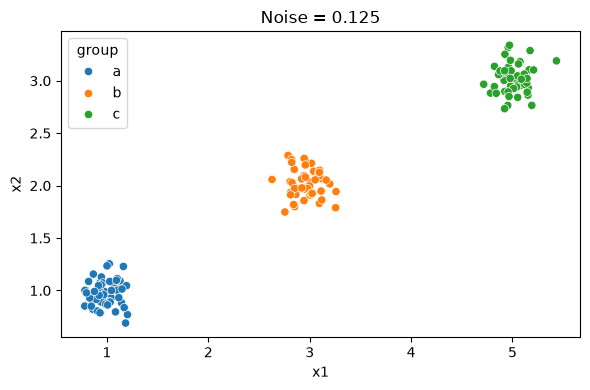

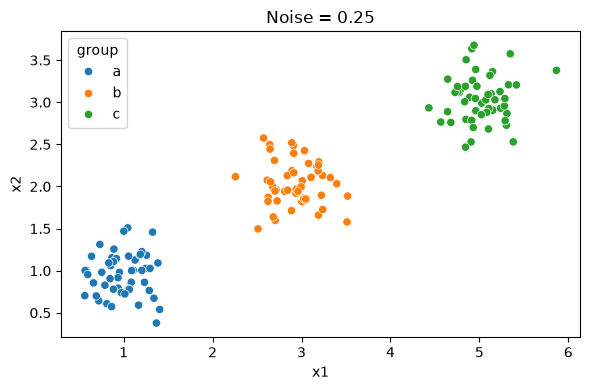

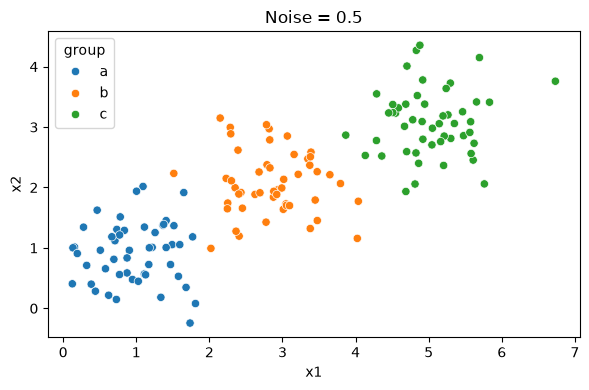

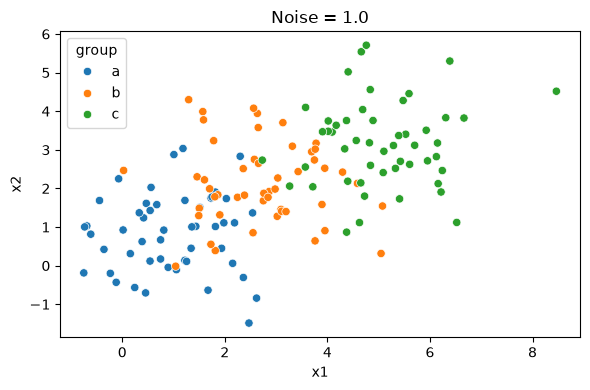

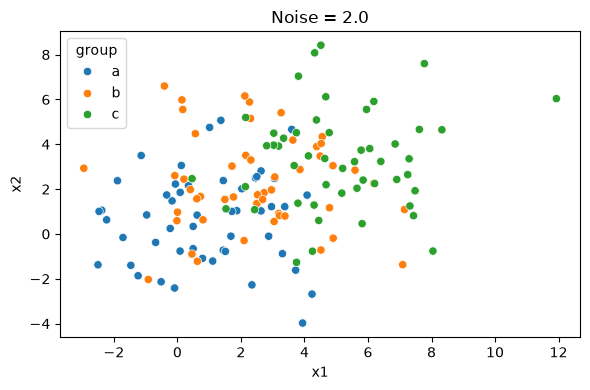

In [2]:

# scatter plots of the datasets with the noise levels 
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]

for i in range(5):
    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=datasets[i], x="x1", y="x2", hue="group")
    plt.title("Noise = " + str(noises[i]))
    plt.tight_layout()
    plt.show()

At the noise At 0.5 we can se ethe gorups are spread out but 3 are visible and at 1 the groups overlap. 2.0 I see alot of overlap so it is not that easy to figure out the 3 original groups from the points alone

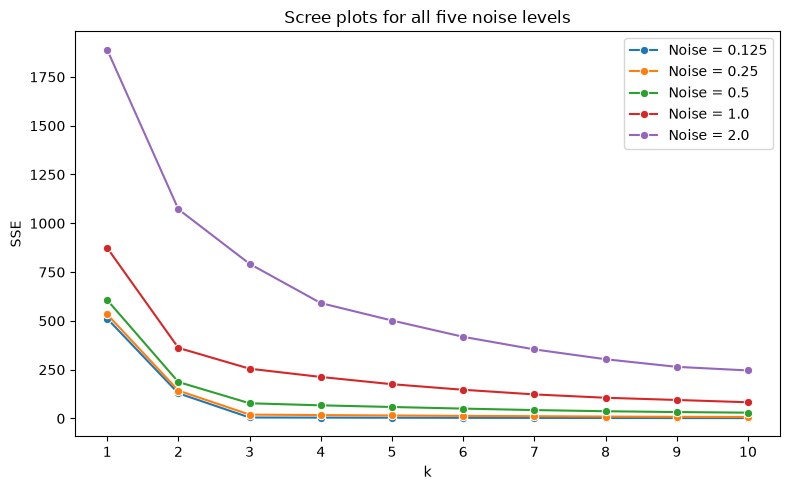

In [4]:
ks = range(1, 11)
plt.figure(figsize=(8, 5))

for i in range(5):
    X = datasets[i][["x1", "x2"]]
    SSE = []
    for k in ks:
        model = KMeans(n_clusters=k, n_init=10, max_iter=300, random_state=0)
        model.fit(X)
        SSE.append(model.inertia_)
    sns.lineplot(x=ks, y=SSE, marker="o", label="Noise = " + str(noises[i]))

plt.title("Scree plots for all five noise levels")
plt.xlabel("k")
plt.ylabel("SSE")
plt.xticks(ks)
plt.tight_layout()
plt.show()

WE can see at k= 3 or at noise 0.125 and 0.25 we can see the elbow . At 0.5 the 3 is a good choice because the curve gets more flat. 1.0 it becomes not as good. 2.0 we can see the curve decreasing more. I think that higher noises increases the SSE because they are more spread out

I think because we dont have a lot of clusters and one in the center has to cover alot of poitns from other groups. Adding another cluster would reduce the SSE since their is one per clear group and they would split up  the groups and the improvement is not as good.



In [6]:
df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
df = df.loc[df["Year"] == 2020].dropna().copy()

# percents are stored as factions i need to convert to percentages
df["Percent of Government Spending"] = df["Percent of Government Spending"] * 100
df["Percent of GDP"] = df["Percent of GDP"] * 100

print("Countries remaining:", len(df))
print(df.dtypes)
df.head()

Countries remaining: 148
index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,1.358857,4.972825,7.181899
66,66,2020,Albania,187.433234,1.258268,3.795233,65.126211
100,100,2020,Algeria,9708.277440,6.659994,17.392427,221.392384
134,134,2020,Angola,993.594405,1.444163,7.462364,30.231680
168,168,2020,Argentina,2830.929705,0.726856,1.726830,62.636731


There are around 148 countries after the 2020 and removing the missing and the 4 spending variables are numbers. The index column is a row number and year is constant.

The percent columns have factions and multiplying by 100 makes it easier to read. Beides the missing rowss I don't think we need to clean this any further 

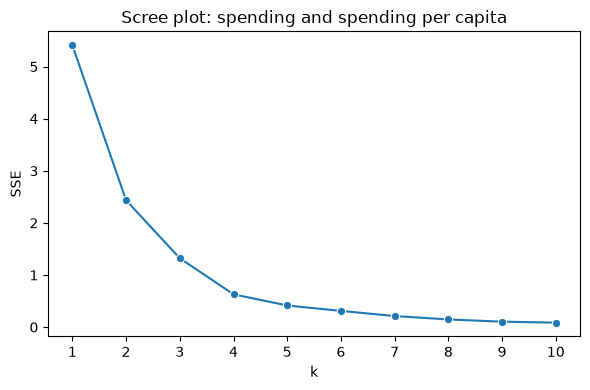

In [8]:
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df[features]

# i am using min max scaling  to scale the data
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, max_iter=300, random_state=0)
    model.fit(X)
    SSE.append(model.inertia_)

plt.figure(figsize=(6, 4))
sns.lineplot(x=ks, y=SSE, marker="o")
plt.title("Scree plot: spending and spending per capita")
plt.xlabel("k")
plt.ylabel("SSE")
plt.xticks(ks)
plt.tight_layout()
plt.show()

I chose 4 becausde it flats more after the 4 clustres. the SSE look like from around 1.3 to like 0.6 when going from 3 to 4 and I htink the elbow method gives a good choices rather than guranteed unique one.

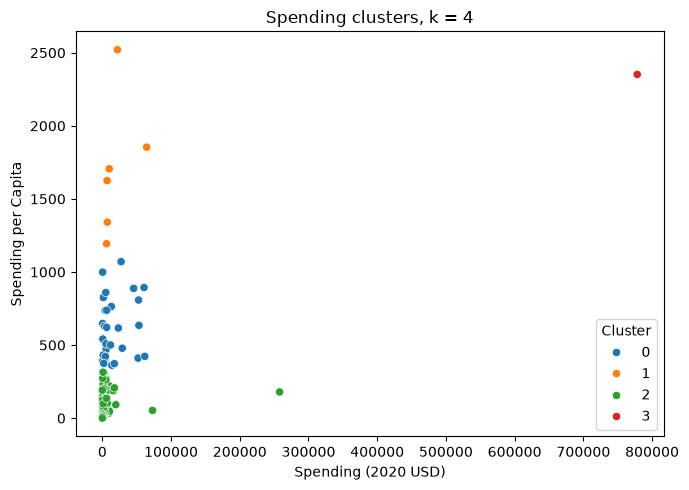

In [10]:
model = KMeans(n_clusters=4, n_init=10, max_iter=300, random_state=0)
model.fit(X)
df["cluster_spending"] = model.labels_

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Spending 2020 USD", y="Spending per capita",
                hue="cluster_spending", palette="tab10")
plt.title("Spending clusters, k = 4")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [12]:
df.groupby("cluster_spending")[features].describe().round(2)

Spending (2020 USD)                                  \
                               count       mean       std        min   
cluster_spending                                                       
0                               30.0   17077.59  20583.05     405.79   
1                                6.0   19443.36  22861.51    6095.71   
2                              111.0    4859.19  25405.74       8.62   
3                                1.0  778397.20       NaN  778397.20   

                                                              \
                        25%        50%        75%        max   
cluster_spending                                               
0                   2294.04    5857.06   26296.00   61712.54   
1                   7023.25    8624.23   18857.07   64558.40   
2                    130.01     382.46    2297.03  257973.43   
3                 778397.20  778397.20  778397.20  778397.20   

                 Spending per Capita                                     \
                               count     mean     std      min      25%   
cluster_spending                                                          
0                               30.0   607.48  206.93   362.47   422.21   
1                                6.0  1706.72  466.38  1193.60  1412.08   
2                              111.0    80.06   83.50     0.58    14.88   
3                                1.0  2351.63     NaN  2351.63  2351.63   

                                             
                      50%      75%      max  
cluster_spending                             
0                  579.00   757.33  1070.62  
1                 1665.45  1817.22  2520.40  
2                   47.06   125.39   314.20  
3                 2351.63  2351.63  2351.63

In [14]:
df.loc[df["Country"] == "United States of America",
       ["Country", "Spending (2020 USD)", "Spending per Capita", "cluster_spending"]]

,Country,Spending (2020 USD),Spending per Capita,cluster_spending
5540,United States of America,778397.2,2351.631858,3


The second clsuter has 111 countires with not alot of psending per perosn. cluster 0 has 30 with kind of a good amoutn of spending perwith around 607. First sluter has 6 countries with high spending per perosn.

The USA is by itself in cluster 3. It has the largest toal spending and 2nd in highest spending per perosn among the 148. I think the cluster numebrs are just labels anda larger cluster number does not mean they spend more

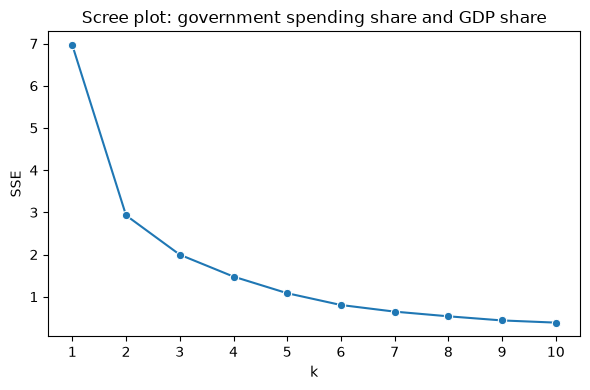

In [16]:
features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = df[features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, max_iter=300, random_state=0)
    model.fit(X)
    SSE.append(model.inertia_)

plt.figure(figsize=(6, 4))
sns.lineplot(x=ks, y=SSE, marker="o")
plt.title("Scree plot: government spending share and GDP share")
plt.xlabel("k")
plt.ylabel("SSE")
plt.xticks(ks)
plt.tight_layout()
plt.show()

I personally chose 2 for a simply summary of lower and higher spending vals. The SSE fals with the 2 clusters. The biggest change in the rate of improvment looks to be 2. The reamaning curve is gradual so this choise is less definie than the spending example.

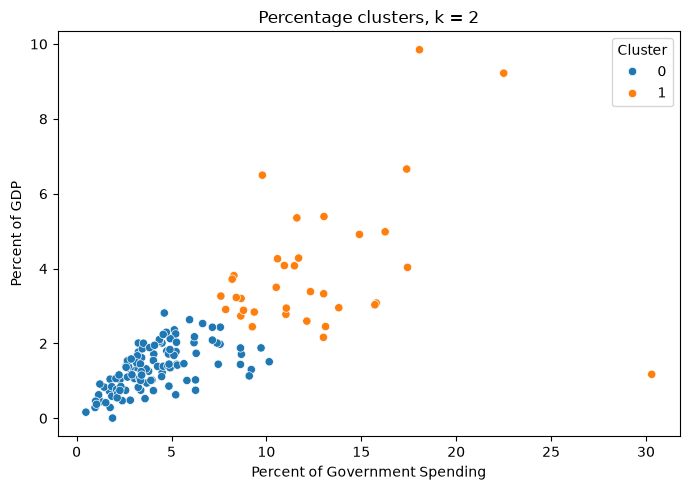

In [18]:
model = KMeans(n_clusters=2, n_init=10, max_iter=300, random_state=0)
model.fit(X)
df["cluster_percent"] = model.labels_

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Percent of Government Spending", y="Percent of GDP",
                hue="cluster_percent", palette="tab10")
plt.title("Percentage clusters, k = 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [20]:
df.groupby("cluster_percent")[features].describe().round(2)

Percent of Government Spending                           \
                                         count   mean   std   min   25%   
cluster_percent                                                           
0                                        113.0   4.14  2.07  0.49  2.68   
1                                         35.0  12.65  4.62  7.60  9.31   

                                     Percent of GDP                          \
                   50%    75%    max          count  mean   std   min   25%   
cluster_percent                                                               
0                 3.85   5.15  10.15          113.0  1.35  0.60  0.01  0.91   
1                11.61  14.36  30.30           35.0  3.94  1.82  1.17  2.90   

                                   
                  50%   75%   max  
cluster_percent                    
0                1.36  1.78  2.81  
1                3.33  4.27  9.85

In [22]:
df.loc[df["Country"] == "United States of America",
       ["Country", "Percent of Government Spending", "Percent of GDP", "cluster_percent"]]

,Country,Percent of Government Spending,Percent of GDP,cluster_percent
5540,United States of America,8.197624,3.717885,1


The 0 cluster has around 113 countires with around 4.14 spending of voerment and 1.35 gdp and the first cluster has 35 with abotu 12.65 and 3.94 govemrent spending of gdp.

The USA is in clsuter 1 with about 8.20% of spending and 3.72% gdp. It shares a cluster with countires that give alot to the military. These things measure the miltary share of a countys budget and ecoomy.

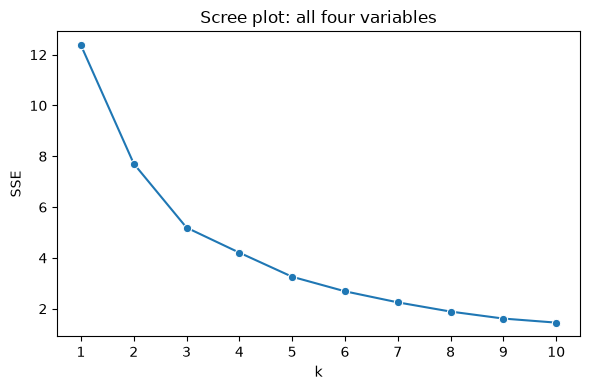

In [24]:
features = ["Spending (2020 USD)", "Spending per Capita",
            "Percent of Government Spending", "Percent of GDP"]
unscaled = df[features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, max_iter=300, random_state=0)
    model.fit(X)
    SSE.append(model.inertia_)

plt.figure(figsize=(6, 4))
sns.lineplot(x=ks, y=SSE, marker="o")
plt.title("Scree plot: all four variables")
plt.xlabel("k")
plt.ylabel("SSE")
plt.xticks(ks)
plt.tight_layout()
plt.show()

I chose 3 because the curve more flat after 3. The SSE looks to be around 12, 7, 5, 4 for each 1,2,3,4. Impromvent i can see from 3-4 clusters is smalller than the ealrier ones. The elbow is not sharp so 3 is reasonable.

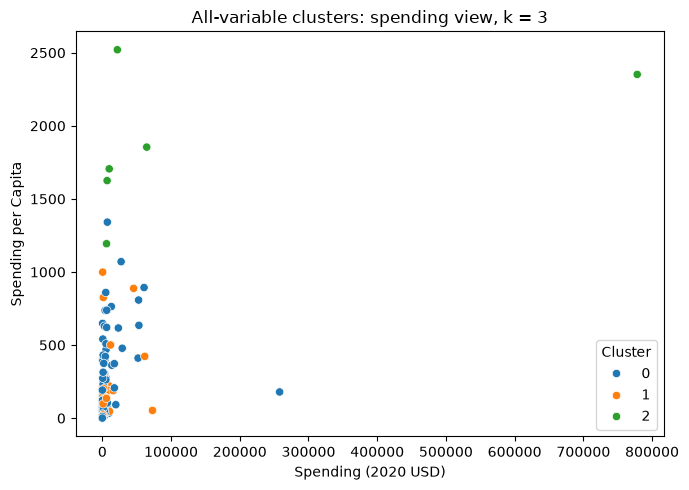

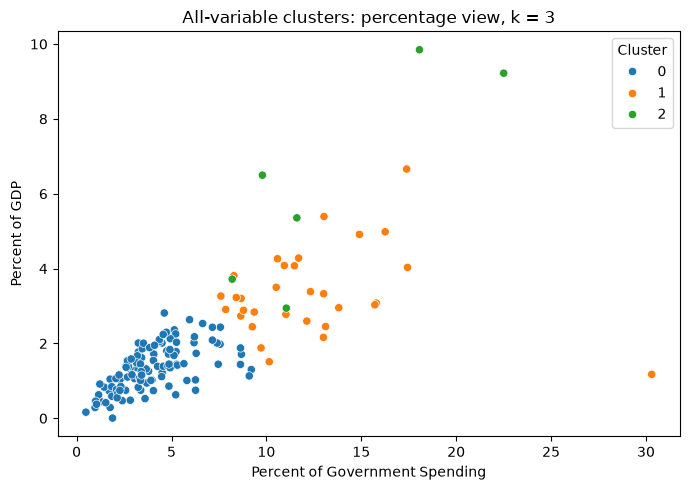

In [26]:
model = KMeans(n_clusters=3, n_init=10, max_iter=300, random_state=0)
model.fit(X)
df["cluster_all"] = model.labels_

# this shwos all the 4 clusters in the 2 variable views
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Spending (2020 USD)", y="Spending per Capita",
                hue="cluster_all", palette="tab10")
plt.title("All-variable clusters: spending view, k = 3")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Percent of Government Spending", y="Percent of GDP",
                hue="cluster_all", palette="tab10")
plt.title("All-variable clusters: percentage view, k = 3")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [28]:
df.groupby("cluster_all")[features].describe().round(2)

Spending (2020 USD)                                          \
                          count       mean        std      min      25%   
cluster_all                                                               
0                         111.0    7086.47   26479.38     8.62   130.01   
1                          31.0    8786.09   17901.91   162.37   467.79   
2                           6.0  147964.58  309635.19  6095.71  7700.42   

                                           Spending per Capita           ...  \
                  50%       75%        max               count     mean  ...   
cluster_all                                                              ...   
0              567.65   3910.11  257973.43               111.0   196.93  ...   
1             1404.79   7739.17   72937.06                31.0   212.69  ...   
2            15897.57  53872.94  778397.20                 6.0  1875.15  ...   

            Percent of Government Spending        Percent of GDP              \
                                       75%    max          count  mean   std   
cluster_all                                                                    
0                                     5.05   9.20          111.0  1.34  0.60   
1                                    13.47  30.30           31.0  3.35  1.14   
2                                    16.45  22.51            6.0  6.26  2.83   

                                           
              min   25%   50%   75%   max  
cluster_all                                
0            0.01  0.89  1.36  1.78  2.81  
1            1.17  2.76  3.20  4.05  6.66  
2            2.94  4.13  5.93  8.54  9.85  

[3 rows x 32 columns]

In [30]:
us_cluster = df.loc[df["Country"] == "United States of America", "cluster_all"].iloc[0]
df.loc[df["cluster_all"] == us_cluster, ["Country", "cluster_all"]]

,Country,cluster_all
2582,Israel,2
2922,Kuwait,2
4044,Oman,2
4486,Saudi Arabia,2
4656,Singapore,2
5540,United States of America,2


The 0 cluster has 111 countires with lower average miltiary spendig per person of about 197 and cluster 1 has 31 with higher but similar spenidng per person. Cluster 2 has 6 countires with high spending per person.

The usa is in cluster 2 and having all 4 varibales it shares the group with other people who spend alot. 

The clusters are different from before because both the variables and k got changed. Comparing these models does not change the effect of adding variables

I think yes and the clusters that showed the total spending and per person and the miltary ones show different aspects of a coutnry and how they spend thier miltary money. The usa stands out in spending while the others devote alot to miltary and using the 4 variabels combined these into a bigger summary.

The groups all depnd on the variables and k and the clusters are useful for fidnign similarities but the elbow method does not always give one clear number of clusters.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

### *Reflection on AI assistance
In your own words without generative AI.